# 2022 — RLHF: Reinforcement Learning from Human Feedback (InstructGPT)

**Papers:** Long Ouyang et al., *"Training language models to follow instructions with human feedback"*, NeurIPS (2022) (InstructGPT, the method behind ChatGPT). Earlier: Christiano et al., *"Deep reinforcement learning from human preferences"* (2017); Stiennon et al., *"Learning to summarize from human feedback"* (2020). Reward over-optimization: Gao, Schulman & Hilton (2022).

A pre-trained LM imitates its training text; it is not trying to be helpful. InstructGPT aligned GPT-3 with what people want in three steps:

1. **SFT:** fine-tune on demonstrations written by people.
2. **Reward model (RM):** people compare two model outputs for the same prompt. Train a model $r_\phi$ to score them, with the Bradley–Terry loss $-\log\sigma\big(r_\phi(y_{win}) - r_\phi(y_{lose})\big)$.
3. **RL with PPO** (notebook 38): maximise the learned reward, with a penalty for drifting from the SFT model $\pi_{ref}$:
$$\max_\pi\ \mathbb E_{y\sim\pi}\big[r_\phi(y)\big] - \beta\,\mathrm{KL}\big(\pi\,\Vert\,\pi_{ref}\big)$$

A 1.3B InstructGPT model was preferred by labellers over the 175B GPT-3. The KL term matters because the RM is only an approximation of human judgement: optimise it too hard and the policy finds outputs the RM scores highly but people would not ("reward hacking", Goodhart's law).

**Toy version.** The "human" is a hidden labelling function: it prefers continuations that **mention the teacher or say "carefully"**, and strongly dislikes **gibberish** (words that are not real words of the corpus). Only pairwise comparisons from this labeller are given to the reward model. We can then measure what RLHF actually does to the true preference, not just to the learned reward.

![Diagram: RLHF / InstructGPT (Ouyang et al., 2022)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/57_2022_rlhf_instructgpt.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
# A procedurally generated corpus (~290K characters) with a real held-out split.
_rng = random.Random(0)
_subjects = ["the model", "a small network", "the optimizer", "each layer", "the attention head", "the router", "a student", "the teacher"]
_verbs = ["learns", "predicts", "updates", "compresses", "routes", "remembers", "forgets", "copies"]
_objects = ["the next token", "a hidden state", "the gradient", "its weights", "a long context", "the key and value", "every expert", "the loss"]
_advs = ["quickly", "slowly", "carefully", "in parallel", "step by step", "without labels", "at scale", "once again"]
def _sentence():
    s = f"{_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)} {_rng.choice(_advs)}"
    if _rng.random() < 0.4: s += f" because {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    if _rng.random() < 0.2: s += f", then {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    return s[0].upper() + s[1:] + ". "
text = "".join(_sentence() for _ in range(4000))
chars = sorted(set(text)); V = len(chars); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], device=device)
split = int(0.9 * len(data)); train_data, val_data = data[:split], data[split:]
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(chars[i] for i in ids)
print(f"{len(text):,} characters, vocab {V}")

290,321 characters, vocab 31


In [3]:
class Block(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.proj, self.h = nn.Linear(d, 3 * d), nn.Linear(d, d), heads
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(self.ln1(x)).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        x = x + self.proj(F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(B, T, D))
        return x + self.mlp(self.ln2(x))

class GPT(nn.Module):
    """A small GPT-2-style character model (pre-norm blocks, learned positions)."""
    def __init__(self, V, d=128, n_layers=4, heads=4, ctx=128):
        super().__init__()
        self.ctx = ctx
        self.tok, self.pos = nn.Embedding(V, d), nn.Embedding(ctx, d)
        self.blocks = nn.ModuleList([Block(d, heads) for _ in range(n_layers)])
        self.ln, self.head = nn.LayerNorm(d), nn.Linear(d, V, bias=False)
    def forward(self, idx):
        x = self.tok(idx) + self.pos(torch.arange(idx.shape[1], device=idx.device))
        for b in self.blocks: x = b(x)
        return self.head(self.ln(x))

def train_gpt(model, train_data, steps=800, B=32, lr=2e-3):
    model = model.to(train_data.device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.1)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.1)
    for s in range(steps):
        ix = torch.randint(0, len(train_data) - model.ctx - 1, (B,), device=train_data.device)
        x = train_data[ix[:, None] + torch.arange(model.ctx, device=train_data.device)]; y = train_data[ix[:, None] + torch.arange(1, model.ctx + 1, device=train_data.device)]
        loss = F.cross_entropy(model(x).reshape(-1, model.head.out_features), y.reshape(-1))
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    return model.eval()

@torch.no_grad()
def eval_loss(model, data, n=20, B=32):
    g = torch.Generator(device="cpu").manual_seed(123); losses = []
    for _ in range(n):
        ix = torch.randint(0, len(data) - model.ctx - 1, (B,), generator=g).to(data.device)
        x = data[ix[:, None] + torch.arange(model.ctx, device=data.device)]; y = data[ix[:, None] + torch.arange(1, model.ctx + 1, device=data.device)]
        losses.append(F.cross_entropy(model(x).reshape(-1, model.head.out_features), y.reshape(-1)).item())
    return float(np.mean(losses))

## Step 1: the base / SFT model
Our "SFT" model is a small character-level GPT trained on the corpus. (In InstructGPT this step used human-written demonstrations.)

In [4]:
seed_everything(0); t0 = time.time()
sft = train_gpt(GPT(V, ctx=96), train_data, steps=1000)
print(f"base model val loss {eval_loss(sft, val_data):.3f} ({time.time() - t0:.0f}s)")

base model val loss 0.220 (45s)


In [5]:
import re, copy
WORDS = set(re.sub(r"[^a-z ]", " ", text.lower()).split())
def true_reward(s):
    """The hidden labeller. +1 for 'teacher', +1 for 'carefully', -1 per gibberish word."""
    words = re.sub(r"[^a-z ]", " ", s.lower()).split()
    return float("teacher" in words) + float("carefully" in words) - sum(w not in WORDS for w in words)

PROMPTS = ["The model ", "A student ", "Each layer ", "The router ", "The optimizer "]
GEN = 48
@torch.no_grad()
def generate(model, n, temp=1.0, seed=None):
    if seed is not None: torch.manual_seed(seed)
    p = [PROMPTS[i % len(PROMPTS)] for i in range(n)]
    out = []
    for prompt in PROMPTS:                                                   # prompts differ in length: generate per prompt
        k = sum(1 for x in p if x == prompt)
        if k == 0: continue
        ids = torch.tensor([encode(prompt)] * k, device=device)
        for _ in range(GEN):
            logits = model(ids[:, -model.ctx:])[:, -1] / temp
            ids = torch.cat([ids, torch.multinomial(F.softmax(logits, -1), 1)], 1)
        out += [(prompt, ids[i].tolist()) for i in range(k)]
    return out
samples = generate(sft, 10, seed=0)
for prompt, ids in samples[:4]: print(repr(decode(ids)), "→ true reward", true_reward(decode(ids)[len(prompt):]))

'The model forgets every expert quickly. A student updates ' → true reward 0.0
'The model copies a hiddeats its weights carefully. The opt' → true reward -1.0
'A student routes a long context. The attention head rememb' → true reward -1.0
'A student routes the gradient at scale. The attention head' → true reward 0.0


## Step 2: the reward model from pairwise preferences
Sample pairs of continuations from the SFT model, let the hidden labeller pick the one with higher true reward (ties broken randomly, plus 10% label noise, since real labellers disagree), and train a reward model: the same Transformer body with a scalar head on the last token.

In [6]:
class RewardModel(nn.Module):
    def __init__(self, base):
        super().__init__(); self.body = copy.deepcopy(base); self.body.head = nn.Identity(); self.v = nn.Linear(base.head.in_features, 1)
    def forward(self, ids): return self.v(self.body(ids)[:, -1]).squeeze(-1)

def to_tensor(samples):
    L = max(len(ids) for _, ids in samples)
    return torch.tensor([[0] * (L - len(ids)) + ids for _, ids in samples], device=device)   # left-pad so the last token is real
seed_everything(0)
pool = generate(sft, 4000, seed=1)
rew = [true_reward(decode(ids)[len(p):]) for p, ids in pool]
pairs = []
for i in range(0, len(pool) - 1, 2):
    a, b = rew[i], rew[i + 1]; pref = (a > b) if a != b else (random.random() < 0.5)
    if random.random() < 0.1: pref = not pref
    pairs.append((i, i + 1) if pref else (i + 1, i))
ids_all = to_tensor(pool)
rm = RewardModel(sft).to(device); opt = torch.optim.AdamW(rm.parameters(), lr=3e-4, weight_decay=0.01)
tr_pairs, te_pairs = pairs[:1800], pairs[1800:]
for s in range(1500):
    b = [tr_pairs[j] for j in np.random.randint(0, len(tr_pairs), 64)]
    w, l = torch.tensor([x for x, _ in b], device=device), torch.tensor([y for _, y in b], device=device)
    loss = -F.logsigmoid(rm(ids_all[w]) - rm(ids_all[l])).mean(); opt.zero_grad(); loss.backward(); opt.step()
rm.eval()
with torch.no_grad():
    w, l = torch.tensor([x for x, _ in te_pairs], device=device), torch.tensor([y for _, y in te_pairs], device=device)
    print(f"reward model agrees with held-out (noisy) preferences: {(rm(ids_all[w]) > rm(ids_all[l])).float().mean().item():.3f}")
print(f"SFT samples: mean true reward {np.mean(rew):.3f}; with 'teacher' {np.mean([r >= 1 for r in rew]):.2f}; any gibberish word {np.mean([r < 0 for r in rew]):.3f}")

reward model agrees with held-out (noisy) preferences: 0.570
SFT samples: mean true reward -0.551; with 'teacher' 0.06; any gibberish word 0.580


## Step 3: PPO against the reward model, with a KL penalty
The policy starts as a copy of the SFT model. Each iteration samples continuations, scores them with the RM, subtracts $\beta$ times the per-sequence KL estimate $\sum_t \log\frac{\pi(y_t)}{\pi_{ref}(y_t)}$, and takes several clipped PPO steps. For brevity the advantage is the reward minus the batch mean (as in RLOO/GRPO-style methods) rather than InstructGPT's learned value function.

In [7]:
def seq_logprobs(model, ids, n_prompt):
    logp = F.log_softmax(model(ids[:, :-1]), -1).gather(2, ids[:, 1:, None]).squeeze(-1)
    return logp[:, n_prompt - 1:]                                             # only the generated tokens

def rlhf(beta, iters=80, B=64, epochs=4, clip=0.2, lr=2e-5, seed=0):
    seed_everything(seed); policy = copy.deepcopy(sft).train(); opt = torch.optim.AdamW(policy.parameters(), lr=lr)
    hist = []
    for it in range(iters):
        prompt = PROMPTS[it % len(PROMPTS)]; n_p = len(prompt)
        with torch.no_grad():
            ids = torch.tensor([encode(prompt)] * B, device=device)
            for _ in range(GEN): ids = torch.cat([ids, torch.multinomial(F.softmax(policy(ids[:, -policy.ctx:])[:, -1], -1), 1)], 1)
            old_lp, ref_lp = seq_logprobs(policy, ids, n_p), seq_logprobs(sft, ids, n_p)
            kl = (old_lp - ref_lp).sum(1)
            r_rm = rm(ids); r = r_rm - beta * kl
            adv = (r - r.mean()) / (r.std() + 1e-8)
        for _ in range(epochs):
            lp = seq_logprobs(policy, ids, n_p); ratio = (lp - old_lp).exp()
            loss = -torch.min(ratio * adv[:, None], ratio.clamp(1 - clip, 1 + clip) * adv[:, None]).mean()
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(policy.parameters(), 1.0); opt.step()
        texts = [decode(x)[n_p:] for x in ids.tolist()]
        hist.append((r_rm.mean().item(), kl.mean().item(), np.mean([true_reward(t) for t in texts]), np.mean([true_reward(t) < 0 for t in texts]), len(set(texts)) / len(texts)))
    return policy.eval(), np.array(hist)

runs = {}
for beta in [0.0, 0.2, 1.0]:
    t0 = time.time(); runs[beta] = rlhf(beta); h = runs[beta][1]
    print(f"β = {beta:4.2f}: RM reward {h[:5, 0].mean():+.2f} → {h[-10:, 0].mean():+.2f} | KL to SFT {h[-10:, 1].mean():6.1f} nats | "
          f"TRUE reward {h[:5, 2].mean():+.2f} → {h[-10:, 2].mean():+.2f} | gibberish rate {h[-10:, 3].mean():.2f} | distinct samples {h[:5, 4].mean():.2f} → {h[-10:, 4].mean():.2f} | {time.time() - t0:.0f}s")

β = 0.00: RM reward +1.05 → +8.63 | KL to SFT   15.0 nats | TRUE reward -0.57 → +0.21 | gibberish rate 0.28 | distinct samples 1.00 → 0.56 | 64s


β = 0.20: RM reward +1.05 → +8.36 | KL to SFT    5.9 nats | TRUE reward -0.57 → +0.76 | gibberish rate 0.07 | distinct samples 1.00 → 0.47 | 63s


β = 1.00: RM reward +1.03 → +6.75 | KL to SFT    2.4 nats | TRUE reward -0.57 → +0.29 | gibberish rate 0.08 | distinct samples 1.00 → 0.95 | 62s


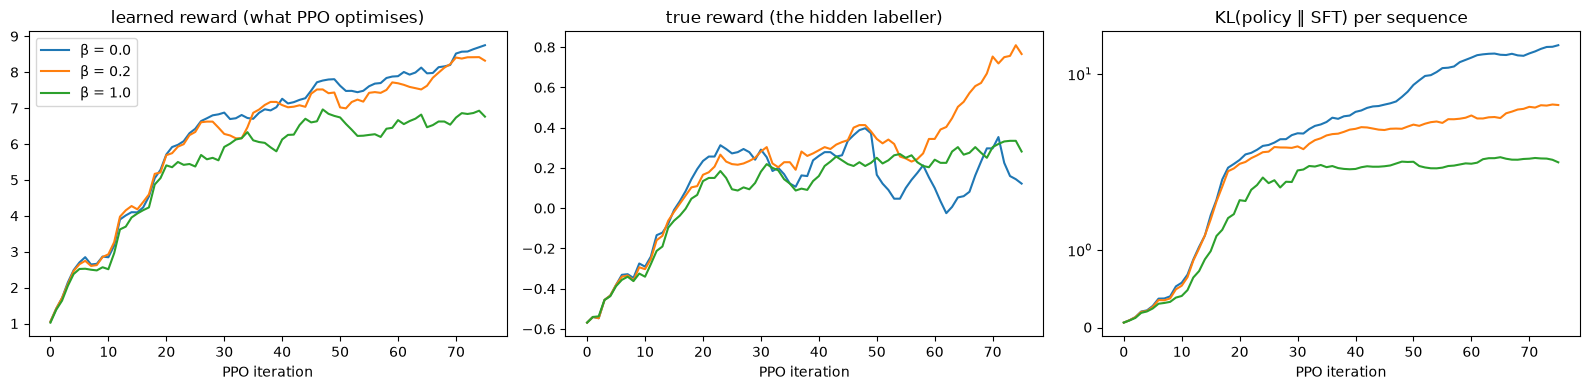

--- β = 0.0


    'The model compresses the los carefully because the teacher'
    'A student compresses the los carefully because the teacher'
    'Each layer updates the loss carefully because the teacher r'
--- β = 0.2


    'The model copies its weights carefully because the teacher'
    'A student copies its weights carefully because the teacher'
    'Each layer updates its weights carefully because the teache'
--- β = 1.0


    'The model predicts a hidden state carefully. The model lea'
    'A student predicts a hidden state carefully. The teacher u'
    'Each layer updates its weights carefully because the router'


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for beta, (_, h) in runs.items():
    sm = lambda v: np.convolve(v, np.ones(5) / 5, mode="valid")
    axes[0].plot(sm(h[:, 0]), label=f"β = {beta}"); axes[1].plot(sm(h[:, 2]), label=f"β = {beta}"); axes[2].plot(sm(h[:, 1]), label=f"β = {beta}")
axes[0].set(title="learned reward (what PPO optimises)", xlabel="PPO iteration"); axes[1].set(title="true reward (the hidden labeller)", xlabel="PPO iteration")
axes[2].set(title="KL(policy ‖ SFT) per sequence", xlabel="PPO iteration", yscale="symlog"); axes[0].legend()
plt.tight_layout(); plt.show()
for beta, (pol, _) in runs.items():
    print(f"--- β = {beta}")
    for prompt, ids in generate(pol, 3, seed=5): print("   ", repr(decode(ids)))

## Takeaways
- **Preferences → reward model → RL.** Comparisons are easier to collect than demonstrations, and the RM turns them into a dense training signal for any output the policy produces.
- **The KL penalty is not decoration.** The RM is an imperfect proxy (it saw only SFT-like text and noisy labels; it agrees with held-out preferences only modestly). In the run above, all three policies push the learned reward from about +1 to +7…+9, but the true reward tells a different story. With $\beta=0$ the policy drifts furthest (KL ≈ 15 nats) and produces the most gibberish (28% of samples, e.g. "the los"), which the RM never learned to punish: reward hacking. A moderate $\beta=0.2$ gives the best true reward with little gibberish. A large $\beta=1$ keeps samples diverse and close to the SFT model but gains less. That trade-off is why $\beta$ is tuned in practice.
- **Mode collapse is a real side effect:** with weak or moderate KL, about half the samples become duplicates of a few high-reward sentences, a small-scale version of the reduced output diversity reported for RLHF-tuned models.
- **What came next:** DPO (notebook 58) removes the explicit RM and the RL loop by solving for the optimal policy in closed form; RL with verifiable rewards (GRPO, notebook 69) replaces the learned RM with a checker wherever answers can be verified, which removes this kind of reward hacking for maths and code.